# 01 · Análise exploratória dos dados (SP156)
**Projeto ZelaBairro · Global Solution 2026/2 · IA & Chatbot**

**Integrantes (turma 1TDSPV):** Leonardo Afonço Sousa (RM 573982) · Syang Cristina Gomes Souza (RM 569259) ·
Matheus Jones Sousa de Freitas (RM 573559) · Vitor Goncalves de Souza (RM 569023) · Joao Machado Nascimento (RM 572364)

Objetivo: entender os chamados reais de zeladoria da Prefeitura de São Paulo antes de treinar os
modelos: o que temos, o quanto está sujo, e se existe sinal para prever **prazo** e **atraso**.

**Fonte e data de acesso dos dados (Documento Base, seção 7.1):**

In [1]:
FONTE = "Dados do SP156 — SMIT, Portal de Dados Abertos da Prefeitura de São Paulo (dados.prefeitura.sp.gov.br, conjunto dados-do-sp156)"
DATA_ACESSO = "15/11/2026"   # dia em que conferimos o conjunto no portal (padrão ABNT: "Acesso em")
VERSAO = "arquivos trimestrais na versão atualizada pelo portal em 10/08/2026"
RECORTE = "chamados abertos de 01/01/2020 a 30/09/2023 (os arquivos usados não traziam o 2º tri/2023)"
print(FONTE); print("Acesso em:", DATA_ACESSO, "|", VERSAO); print("Recorte:", RECORTE)

Dados do SP156 — SMIT, Portal de Dados Abertos da Prefeitura de São Paulo (dados.prefeitura.sp.gov.br, conjunto dados-do-sp156)
Acesso em: 15/11/2026 | arquivos trimestrais na versão atualizada pelo portal em 10/08/2026
Recorte: chamados abertos de 01/01/2020 a 30/09/2023 (os arquivos usados não traziam o 2º tri/2023)


## 1. Carga e visão geral

In [2]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = os.path.abspath("..")           # este notebook roda dentro de notebooks/
sys.path.insert(0, RAIZ)               # para importar ml_utils e chatbot
from chatbot.intents import CATEGORIAS # tabela 6.4 do Documento Base (prazos e gravidades)

CAMINHO_DADOS = os.path.join(RAIZ, "data", "dados_sp156.csv")
df = pd.read_csv(CAMINHO_DADOS)
print(f"{len(df):,} linhas e {df.shape[1]} colunas carregadas de {os.path.relpath(CAMINHO_DADOS, RAIZ)}")
df.head()

982,475 linhas e 9 colunas carregadas de data/dados_sp156.csv


,categoria,subprefeitura,data_abertura,data_encerramento,mes,dia_semana,dias_para_resolver,nr_prazo_dias,atrasou
0,Descarte irregular de lixo,Freguesia/Brasilândia,2020-01-01,2020-03-17,1,2,76,10,1
1,Buraco na via,Freguesia/Brasilândia,2020-01-01,2020-01-14,1,2,13,15,0
2,Buraco na via,Freguesia/Brasilândia,2020-01-01,2020-03-16,1,2,75,15,1
3,Buraco na via,Santo Amaro,2020-01-01,2020-01-08,1,2,7,15,0
4,Buraco na via,São Mateus,2020-01-01,2020-04-23,1,2,113,15,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 982475 entries, 0 to 982474
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   categoria           982475 non-null  str  
 1   subprefeitura       982475 non-null  str  
 2   data_abertura       982475 non-null  str  
 3   data_encerramento   982475 non-null  str  
 4   mes                 982475 non-null  int64
 5   dia_semana          982475 non-null  int64
 6   dias_para_resolver  982475 non-null  int64
 7   nr_prazo_dias       982475 non-null  int64
 8   atrasou             982475 non-null  int64
dtypes: int64(5), str(4)
memory usage: 67.5 MB


In [4]:
esperadas = ["categoria", "subprefeitura", "mes", "dia_semana", "dias_para_resolver", "nr_prazo_dias", "atrasou"]
faltando = [c for c in esperadas if c not in df.columns]
assert not faltando, f"Colunas ausentes: {faltando}. Rode scripts/preparar_dados.py"
print("Nulos por coluna:"); print(df[esperadas].isna().sum())
print("\nLinhas idênticas (esperado: sem hora/protocolo, são chamados diferentes no mesmo dia/distrito):", df.duplicated().sum())
print("Categorias fora da tabela 6.4:", sorted(set(df['categoria']) - set(CATEGORIAS)))

Nulos por coluna:
categoria             0
subprefeitura         0
mes                   0
dia_semana            0
dias_para_resolver    0
nr_prazo_dias         0
atrasou               0
dtype: int64



Linhas idênticas (esperado: sem hora/protocolo, são chamados diferentes no mesmo dia/distrito): 464478
Categorias fora da tabela 6.4: []


## 2. Como os dados foram preparados
O arquivo `data/dados_sp156.csv` vem de `scripts/preparar_dados.py` a partir dos CSVs **trimestrais** do SP156:
1. fica só com os **serviços** que correspondem às categorias do ZelaBairro (de-para por serviço em `data/depara_sp156.csv`);
2. fica só com chamados de status **FINALIZADA**; remove linhas repetidas **entre** arquivos, mas mantém linhas idênticas dentro do mesmo
   arquivo (de 2020 em diante o SP156 não traz hora nem protocolo, então duas linhas iguais são chamados diferentes);
3. `dias_para_resolver = data do parecer − data de abertura` (em dias);
4. a subprefeitura é derivada do **distrito** (`data/depara_distrito_subprefeitura.csv`). Conferência: de 2020 a 2023 o SP156 traz também a
   *Prefeitura Operacional* e, em cada distrito, a subprefeitura do nosso mapa coincide com ela na grande maioria dos chamados (as diferenças são
   chamados atendidos por outra subprefeitura);
5. `atrasou = 1` se `dias_para_resolver > nr_prazo_dias` da categoria (**mesma regra da RN11**);
6. `mes` (1–12) e `dia_semana` (0 = segunda … 6 = domingo, igual ao `weekday()` do Python) saem da data de abertura.

### Por que só 2020–2023? (decisão tomada olhando os dados)
A coluna de encerramento é a única data de fim que o SP156 traz, e o que ela mede **muda com o tempo**:
* **2012–2014:** estrutura diferente (sem distrito). **2015 até 3º tri/2016, 2018 e 2019:** o parecer cai no **mesmo dia da abertura em 73–100% dos
  chamados** (não mede atendimento). jan–set/2017 serve, mas é só um ano parcial e antigo.
* **A partir de 2020** o arquivo passa a ter **"Data de Finalização"**: só 8–18% caem no mesmo dia e as medianas são plausíveis.
Por isso o treino usa **1º tri/2020 a 3º tri/2023** (14 trimestres; o 2º tri/2023 não foi fornecido). A célula abaixo mostra isso no dado usado.

In [5]:
df["_ab"] = pd.to_datetime(df["data_abertura"])
z = df.groupby(df["_ab"].dt.to_period("M"))["dias_para_resolver"].agg(chamados="size", pct_mesmo_dia=lambda s: round(100 * (s == 0).mean(), 1))
print("Janela usada:", df["data_abertura"].min(), "a", df["data_abertura"].max())
z

Janela usada: 2020-01-01 a 2023-09-30


,chamados,pct_mesmo_dia
_ab,,
2020-01,26810,7.6
2020-02,27204,7.9
2020-03,22174,8.9
2020-04,11318,13.6
2020-05,11481,14.8
2020-06,16515,16.0
2020-07,18727,16.7
2020-08,17987,18.6
2020-09,18991,18.7


In [6]:
MINIMO = 200  # mesmo limite do predictor.py: abaixo disso a categoria é "sem histórico suficiente"
cob = df["categoria"].value_counts().reindex(list(CATEGORIAS)).fillna(0).astype(int).to_frame("chamados")
cob["histórico suficiente?"] = np.where(cob["chamados"] >= MINIMO, "sim", "NÃO — o chatbot não mostra previsão")
cob

,chamados,histórico suficiente?
categoria,,
Buraco na via,474597,sim
Iluminação pública apagada,0,NÃO — o chatbot não mostra previsão
Descarte irregular de lixo,170435,sim
Árvore com risco de queda,19685,sim
Poda de árvore,205595,sim
Calçada danificada,9400,sim
Bueiro entupido,86757,sim
Sinalização de trânsito danificada,16006,sim


## 3. Volume por categoria e por subprefeitura

**Como escolhemos os gráficos (framework de Dataviz da Aula 04):** para cada gráfico, (1) a **pergunta de negócio** vira o título,
(2) identificamos as **variáveis** (categoria = nominal; quantidade e % = quantitativas) e (3) escolhemos o gráfico pela **taxonomia**:
comparação entre categorias → **barras horizontais** (comprimento é um dos atributos mais precisos na hierarquia de Cleveland e McGill
e os nomes longos ficam legíveis); distribuição → **histograma** e **boxplot**; evolução no tempo → **linha**. Seguimos a versão
"profissional" da aula: barras 2D em cinza, **só o destaque em cor**, rótulo na ponta da barra e sem grade, pizza ou 3D.

In [7]:
CINZA, DESTAQUE = "#b8bfc6", "#0f5c5a"

def barras(serie, titulo, destaques=(), formato="{:,.0f}", rotulo_x=""):
    """Barras horizontais no padrão da Aula 04: cinza neutro, só os destaques em cor, valor na ponta da barra."""
    serie = serie.sort_values()
    cores = [DESTAQUE if i in destaques else CINZA for i in serie.index]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(serie) + 1))
    ax.barh(serie.index, serie.values, color=cores)
    for i, v in enumerate(serie.values):
        ax.text(v, i, " " + formato.format(v).replace(",", "."), va="center", fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=12); ax.set_xlabel(rotulo_x)
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    ax.margins(x=0.15); plt.tight_layout(); plt.show()

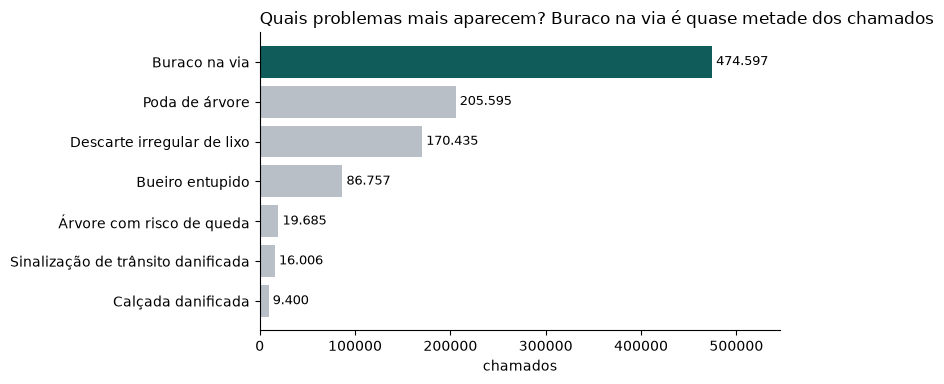

,chamados
categoria,
Buraco na via,474597
Poda de árvore,205595
Descarte irregular de lixo,170435
Bueiro entupido,86757
Árvore com risco de queda,19685
Sinalização de trânsito danificada,16006
Calçada danificada,9400


In [8]:
# Pergunta: quais problemas mais aparecem? (comparação entre categorias → barras horizontais)
por_cat = df["categoria"].value_counts()
barras(por_cat, "Quais problemas mais aparecem? Buraco na via é quase metade dos chamados",
       destaques=[por_cat.idxmax()], rotulo_x="chamados")
por_cat.to_frame("chamados")

In [9]:
sub = df["subprefeitura"].value_counts()
print(f"{sub.size} subprefeituras. Menores grupos (poucos dados = previsão menos confiável):")
sub.tail(8).to_frame("chamados")

32 subprefeituras. Menores grupos (poucos dados = previsão menos confiável):


,chamados
subprefeitura,
Vila Prudente,20763
Jabaquara,19585
Guaianases,15648
Sapopemba,14759
Ermelino Matarazzo,14405
Cidade Tiradentes,10878
Parelheiros,9851
Perus,9568


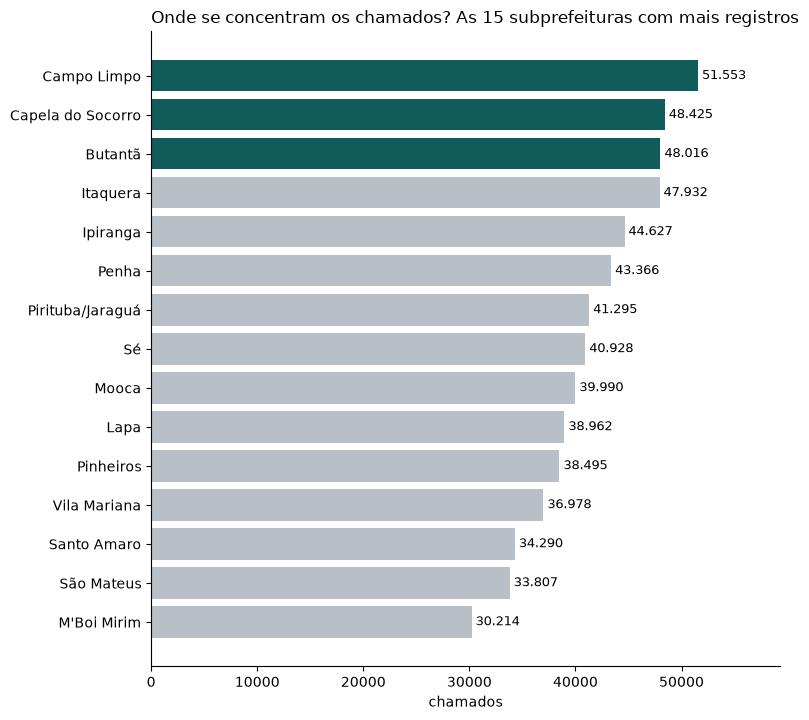

In [10]:
# Pergunta: onde se concentram os chamados? (comparação → barras horizontais, destaque nas 3 maiores)
top15 = sub.head(15)
barras(top15, "Onde se concentram os chamados? As 15 subprefeituras com mais registros",
       destaques=list(top15.index[:3]), rotulo_x="chamados")

## 4. Tempo de resolução (`dias_para_resolver`)

In [11]:
df["dias_para_resolver"].describe(percentiles=[.5, .75, .9, .95, .99]).to_frame("dias")

,dias
count,982475.000000
mean,28.554387
std,62.315363
min,0.000000
50%,7.000000
75%,24.000000
90%,79.000000
95%,139.000000
99%,300.000000
max,1668.000000


### Estatística descritiva do tempo de resolução (Aula 02)
Medidas de tendência central (média, mediana, moda), de dispersão (desvio padrão) e de posição (quartis), e a regra do
**intervalo interquartil (IQR)** para identificar outliers: valores acima de Q3 + 1,5 × IQR.

In [12]:
dias = df["dias_para_resolver"]
media, mediana, moda = dias.mean(), dias.median(), dias.mode()[0]
desvio = dias.std()                       # desvio padrão amostral (stdev da aula)
q1, q2, q3 = dias.quantile([.25, .50, .75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
outliers = (dias > limite_superior).sum()
print(f"Média: {media:.1f} dias | Mediana: {mediana:.0f} dias | Moda: {moda} dias")
print(f"Desvio padrão: {desvio:.1f} dias")
print(f"Q1: {q1:.0f} | Q2 (mediana): {q2:.0f} | Q3: {q3:.0f} | IQR: {iqr:.0f} dias")
print(f"Limite para outlier (Q3 + 1,5 × IQR): {limite_superior:.0f} dias")
print(f"Outliers: {outliers:,} chamados ({outliers / len(dias):.1%}) — o maior levou {dias.max():,} dias")

Média: 28.6 dias | Mediana: 7 dias | Moda: 0 dias
Desvio padrão: 62.3 dias
Q1: 1 | Q2 (mediana): 7 | Q3: 24 | IQR: 23 dias
Limite para outlier (Q3 + 1,5 × IQR): 58 dias
Outliers: 133,691 chamados (13.6%) — o maior levou 1,668 dias


**Interpretação:** a **média é bem maior que a mediana**, o mesmo fenômeno do exemplo de tempo de entrega da Aula 02 (média 10 × mediana 4,5):
poucos chamados muito demorados puxam a média para cima. O desvio padrão alto e a quantidade de outliers confirmam a **cauda longa**.
Consequências para os modelos: (1) usamos o **MAE** como métrica principal, porque ele não é dominado pelos extremos; (2) no modelo de
prazo treinamos sobre **log(1 + dias)**, que reduz o peso dos outliers sem apagá-los (não removemos os chamados longos porque são reais),
e assim o modelo prevê o tempo **típico**, mais próximo da mediana.

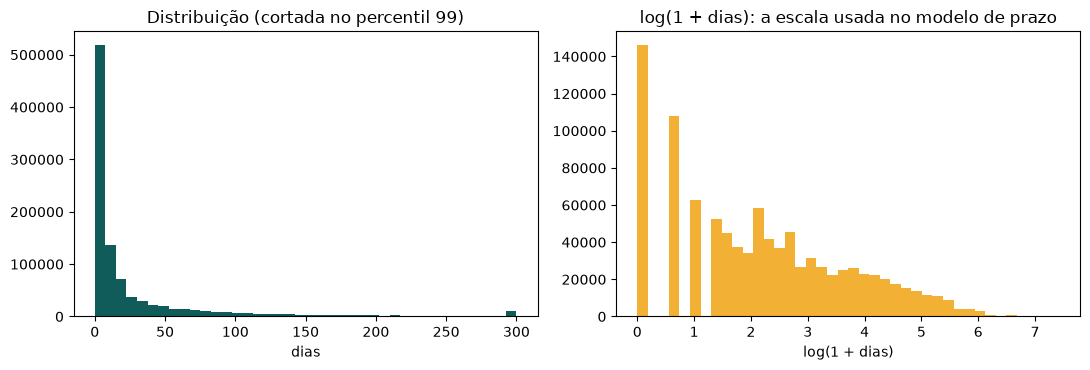

In [13]:
# Pergunta: como o tempo de resolução se distribui? (distribuição → histograma + boxplot)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df["dias_para_resolver"].clip(upper=df["dias_para_resolver"].quantile(.99)).hist(bins=40, ax=ax[0], color="#0f5c5a")
ax[0].set_title("Distribuição (cortada no percentil 99)"); ax[0].set_xlabel("dias"); ax[0].grid(False)
np.log1p(df["dias_para_resolver"]).hist(bins=40, ax=ax[1], color="#f2b134")
ax[1].set_title("log(1 + dias): a escala usada no modelo de prazo"); ax[1].set_xlabel("log(1 + dias)"); ax[1].grid(False)
plt.tight_layout(); plt.show()

In [14]:
resumo = df.groupby("categoria")["dias_para_resolver"].agg(["count", "median", "mean", "std", "max"]).round(1)
resumo["prazo_referencia"] = [CATEGORIAS[c]["prazo_dias"] for c in resumo.index]
resumo.sort_values("median", ascending=False)

,count,median,mean,std,max,prazo_referencia
categoria,,,,,,
Poda de árvore,205595,28.0,60.8,85.3,1448,30
Sinalização de trânsito danificada,16006,18.0,54.4,114.7,1668,10
Calçada danificada,9400,11.0,41.4,82.8,1301,30
Buraco na via,474597,9.0,24.4,47.1,1099,15
Bueiro entupido,86757,1.0,24.8,82.5,1049,10
Descarte irregular de lixo,170435,1.0,3.0,15.5,468,10
Árvore com risco de queda,19685,0.0,2.4,7.6,398,5


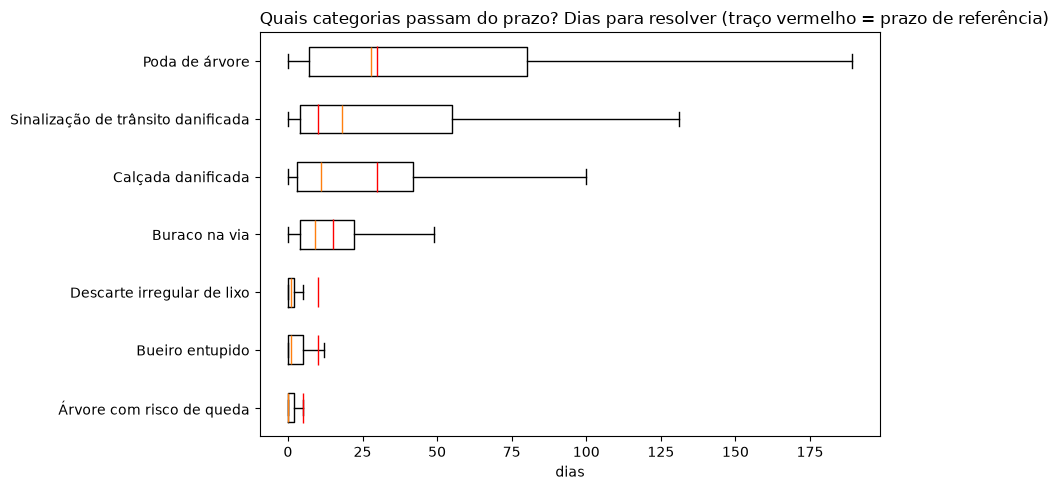

In [15]:
ordem = resumo.sort_values("median").index
dados = [df.loc[df["categoria"] == c, "dias_para_resolver"].clip(upper=df["dias_para_resolver"].quantile(.99)) for c in ordem]
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(dados, vert=False, showfliers=False)
ax.set_yticklabels(list(ordem))   # compatível com qualquer versão do matplotlib
for i, c in enumerate(ordem, 1):
    ax.plot(CATEGORIAS[c]["prazo_dias"], i, "r|", markersize=22)
ax.set_title("Quais categorias passam do prazo? Dias para resolver (traço vermelho = prazo de referência)", loc="left")
ax.set_xlabel("dias"); plt.tight_layout(); plt.show()

**Leitura:** compare a mediana de cada categoria com o traço vermelho (prazo de referência da tabela 6.4).
Categorias cuja mediana já passa do prazo terão muitos atrasos: isso define o equilíbrio de classes do modelo 2.

## 5. Atraso (`atrasou`) — alvo do modelo 2

Proporção geral de atrasos: 29.8%


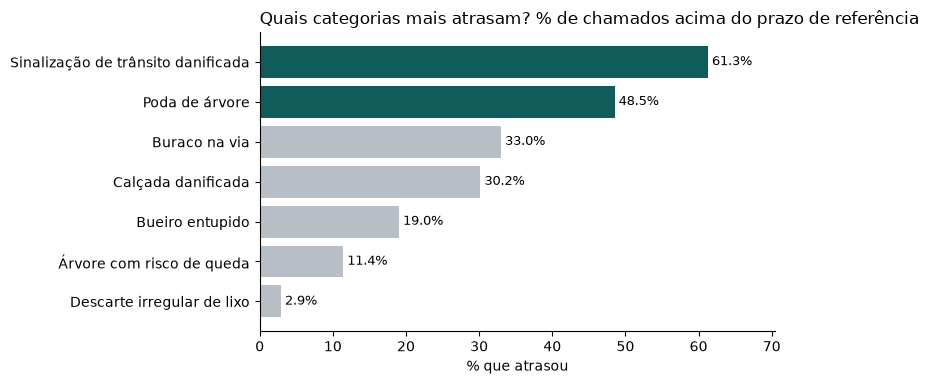

In [16]:
print(f"Proporção geral de atrasos: {df['atrasou'].mean():.1%}")
atraso_cat = df.groupby("categoria")["atrasou"].mean() * 100
# Pergunta: quais categorias mais atrasam? (comparação → barras, destaque nas que atrasam mais da metade das vezes)
barras(atraso_cat, "Quais categorias mais atrasam? % de chamados acima do prazo de referência",
       destaques=list(atraso_cat[atraso_cat > 40].index), formato="{:.1f}%", rotulo_x="% que atrasou")

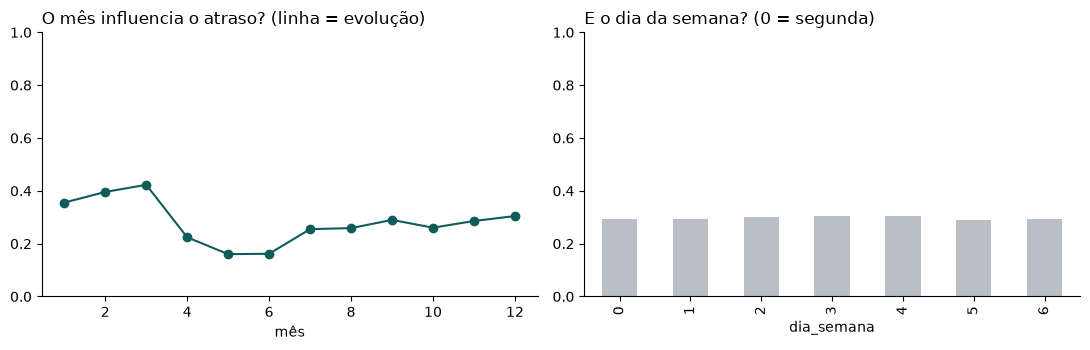

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.groupby("mes")["atrasou"].mean().plot(marker="o", ax=ax[0], color="#0f5c5a")
ax[0].set_title("O mês influencia o atraso? (linha = evolução)", loc="left"); ax[0].set_xlabel("mês"); ax[0].set_ylim(0, 1)
df.groupby("dia_semana")["atrasou"].mean().plot.bar(ax=ax[1], color=CINZA)
ax[1].set_title("E o dia da semana? (0 = segunda)", loc="left"); ax[1].set_ylim(0, 1)
for a in ax:
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

In [18]:
tab = df.pivot_table(index="subprefeitura", columns="categoria", values="atrasou", aggfunc="mean")
sub_atraso = df.groupby("subprefeitura")["atrasou"].agg(["mean", "count"]).query("count >= 30").sort_values("mean")
print("Subprefeituras com pelo menos 30 chamados — menor e maior % de atraso:")
pd.concat([sub_atraso.head(5), sub_atraso.tail(5)]).round(3)

Subprefeituras com pelo menos 30 chamados — menor e maior % de atraso:


,mean,count
subprefeitura,,
Jabaquara,0.137,19585
Jaçanã/Tremembé,0.142,25713
Cidade Tiradentes,0.149,10878
Guaianases,0.187,15648
São Miguel,0.191,25833
Itaim Paulista,0.366,28207
Santo Amaro,0.378,34290
Penha,0.415,43366
Lapa,0.442,38962


## 6. Cuidados com os dados (para citar na apresentação)
* **Viés de sobrevivência quase nulo:** só chamados **finalizados** têm `dias_para_resolver`, mas nos arquivos de 2020–2023 apenas
  0,0–0,4% dos chamados dessas categorias estavam abertos ou cancelados quando o relatório foi gerado. Nenhum veio como "Indeferido".
* **"Data de Finalização" ≠ conserto:** segundo o glossário oficial do SP156 (2020 em diante, `docs/glossario_sp156_2020.txt`), ela é a
  *"data de fechamento do protocolo"*, e o status "Finalizado" significa *"finalizada pelo órgão competente"*. O próprio glossário avisa que o
  SP156 não executa o serviço. O "prazo previsto" do ZelaBairro é, portanto, o **tempo até o órgão fechar o protocolo**.
* **Vários protocolos para o mesmo problema:** o glossário diz que um cidadão pode abrir mais de uma solicitação e várias pessoas podem pedir
  o mesmo serviço. Isso é exatamente o que a RN07 do ZelaBairro (apoiar em vez de duplicar) evita.
* **Categoria sem dados:** "Iluminação pública apagada" não tem chamados no SP156 a partir de 2018 (os serviços de iluminação só aparecem até 2017).
  O modelo não aprendeu nada sobre ela e o chatbot deixa de dar previsão para ela.
* **Pandemia:** 2020 e 2021 incluem a COVID-19, quando o atendimento foi irregular (ex.: buraco teve mediana de 32 dias no 1º tri/2020).
* **Arquivos faltando:** o 2º tri/2023 não foi fornecido. O 2º tri/2021 veio em .xlsx e foi lido normalmente. O CSV também não tem nenhum chamado aberto em fev–mar/2021 (o 1º tri/2021 só traz janeiro); a causa não foi verificada nos arquivos de origem.
* **Fechamento no mesmo dia:** em *Bueiro*, *Descarte* e *Árvore com risco* 45–53% dos chamados têm 0 dia, então o prazo dessas categorias
  é bimodal (muitos em 0–1 dia e uma cauda longa).
* **Prazos de referência × realidade:** compare a mediana real com o prazo da tabela 6.4 (seção 4). Em Sinalização e Poda perto de metade
  ou mais dos chamados passa do prazo; em Descarte quase nenhum passa. Isso define o equilíbrio de classes do modelo 2.
* **Sem vazamento:** os modelos usam só `categoria`, `subprefeitura`, `mes` e `dia_semana`,
  informações que existem **na abertura**. A data de encerramento nunca é entrada.
* **Poucas features:** sem gravidade real do chamado, descrição ou local exato, o poder de previsão é limitado.
  Compare sempre com o baseline (notebooks 02 e 03) antes de afirmar que o modelo "funciona".
* **Subprefeituras pequenas** têm poucos exemplos; o modelo trata nomes nunca vistos sem quebrar
  (`handle_unknown="ignore"`), mas a previsão será mais genérica.

## 7. Conclusões da exploração
* **O que temos:** 982.475 chamados finalizados do SP156, abertos entre janeiro de 2020 e setembro de 2023, em 7 das nossas 8 categorias e 32 subprefeituras, sem valores nulos. Iluminação pública não tem nenhum chamado nesse período, então não vamos conseguir prever nada para ela.
* **Buraco na via domina a base:** sozinho é quase metade dos chamados (474.597, 48,3%). Somando Poda de árvore e Descarte de lixo, chegamos a 86,6%. Calçada (9.400) e Sinalização (16.006) têm poucos exemplos.
* **O tempo de resolução tem muitos valores extremos:** a média é de 28,6 dias, mas a mediana é só 7 e a moda é 0 (muita coisa fecha no mesmo dia). O desvio padrão é de 62,3 dias. Pela regra do IQR (Q3 = 24 e IQR = 23), tudo acima de 58 dias é outlier, o que dá 133.691 chamados (13,6%); o maior levou 1.668 dias. É o mesmo caso do exemplo de tempo de entrega da Aula 02: a média engana. Por isso vamos usar o MAE como métrica principal e treinar o modelo de prazo em log(1 + dias).
* **O tipo de problema é o que mais muda o tempo:** pela mediana, Árvore com risco de queda fecha em 0 dia, Bueiro e Descarte em 1 dia e Poda em 28 dias. Sinalização tem mediana de 18 dias, mesmo com prazo de referência de 10.
* **Atraso:** 29,8% dos chamados passam do prazo da tabela 6.4, então as classes são desbalanceadas (cerca de 70/30). Sinalização atrasa 61,3% das vezes, Poda 48,5% e Buraco 33,0%; Descarte, só 2,9%.
* **Subprefeitura:** entre as que têm pelo menos 30 chamados, o atraso vai de 13,7% (Jabaquara) a 46,0% (Pirituba/Jaraguá). Parte dessa diferença pode ser só a mistura de categorias de cada região.
* **O que esperamos dos modelos:** na abertura do chamado só sabemos categoria, subprefeitura, mês e dia da semana. Com tão pouca informação, o ganho sobre uma tabela de medianas por categoria deve ser pequeno. Por isso, nos notebooks 02 e 03, comparamos sempre com baselines.